In [32]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [33]:
df = pd.read_csv("../data/clean_data/clean_dataset.csv")

In [34]:
df.shape

(8790, 10)

In [35]:
df.columns.tolist()

['show_id',
 'type',
 'title',
 'director',
 'country',
 'date_added',
 'release_year',
 'rating',
 'duration',
 'listed_in']

In [36]:
df.head(
    
)

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [37]:
df["release_year"].dtype

dtype('int64')

In [38]:
df["release_year"].isnull().sum()

np.int64(0)

In [39]:
df["release_year"].min()

np.int64(1925)

In [40]:
df["release_year"].max()

np.int64(2021)

In [41]:
df["release_year"].nunique()

74

In [42]:
df["release_year"] = pd.to_numeric(
    df["release_year"],errors="coerce"
)

year_df = df.dropna(subset=["release_year"]).copy()
year_df["release_year"] = year_df["release_year"].astype(int)

yearly_content = (
    year_df.groupby("release_year").size()
    .reset_index(name="content_count")
)

yearly_content = yearly_content.sort_values("release_year")
yearly_content.head(10)

,release_year,content_count
0,1925,1
1,1942,2
2,1943,3
3,1944,3
4,1945,4
5,1946,2
6,1947,1
7,1954,2
8,1955,3
9,1956,2


In [43]:
yearly_content["release_year"].nunique()

74

In [44]:
yearly_content["content_count"].sum()

np.int64(8790)

In [45]:
yearly_content["content_count"].mean()

np.float64(118.78378378378379)

In [46]:
yearly_content.loc[
    yearly_content["content_count"].idxmax()
]

release_year     2018
content_count    1146
Name: 70, dtype: int64

In [47]:
yearly_content.loc[
    yearly_content["content_count"].idxmin()
]

release_year     1925
content_count       1
Name: 0, dtype: int64

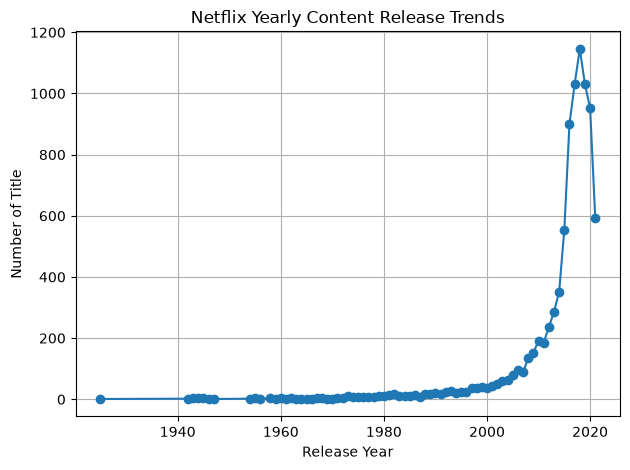

In [48]:
plt.Figure(figsize=(14,6))
plt.plot(
    yearly_content["release_year"],
    yearly_content["content_count"],
    marker="o"
)

plt.title("Netflix Yearly Content Release Trends")
plt.xlabel("Release Year")
plt.ylabel("Number of Title")
plt.grid(True)

plt.tight_layout()
plt.show()

In [49]:
top_years = yearly_content.sort_values(
    by="content_count",
    ascending=False
).head(10)

top_years

,release_year,content_count
70,2018,1146
69,2017,1030
71,2019,1030
72,2020,953
68,2016,901
73,2021,592
67,2015,555
66,2014,352
65,2013,286
64,2012,236


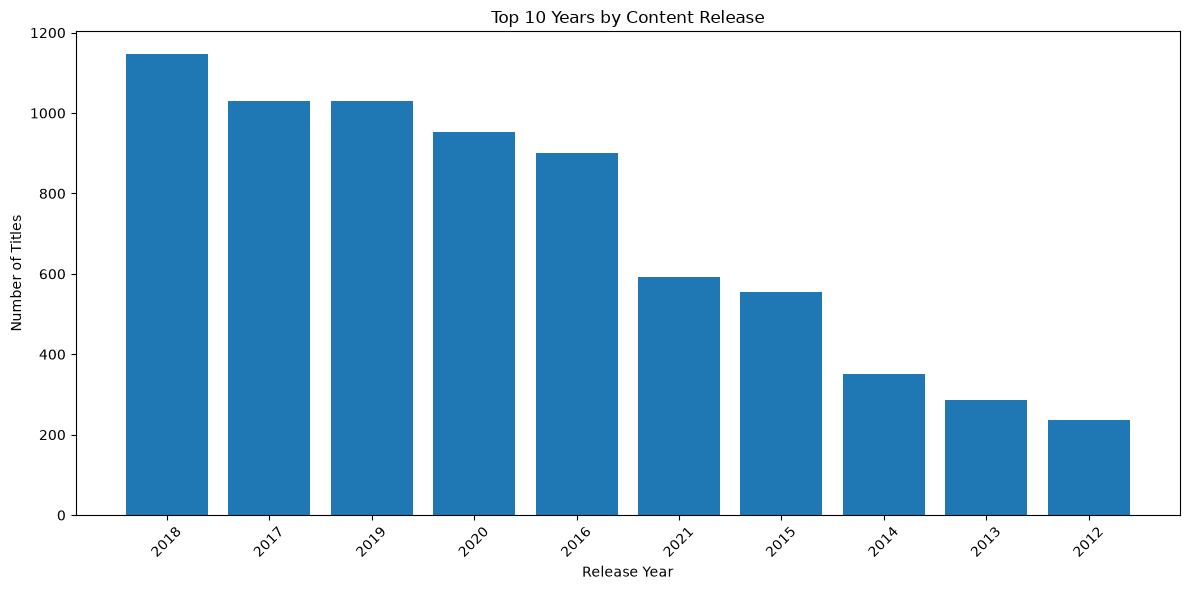

In [50]:
plt.figure(figsize=(12,6))

plt.bar(
    top_years["release_year"].astype(str),
    top_years["content_count"]
)

plt.title("Top 10 Years by Content Release")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [51]:
yearly_type = df.groupby(
    ["release_year","type"]
).size().unstack(fill_value=0)

yearly_type.tail(10)

type,Movie,TV Show
release_year,,
2012,173,63
2013,225,61
2014,264,88
2015,396,159
2016,658,243
2017,765,265
2018,767,379
2019,633,397
2020,517,436


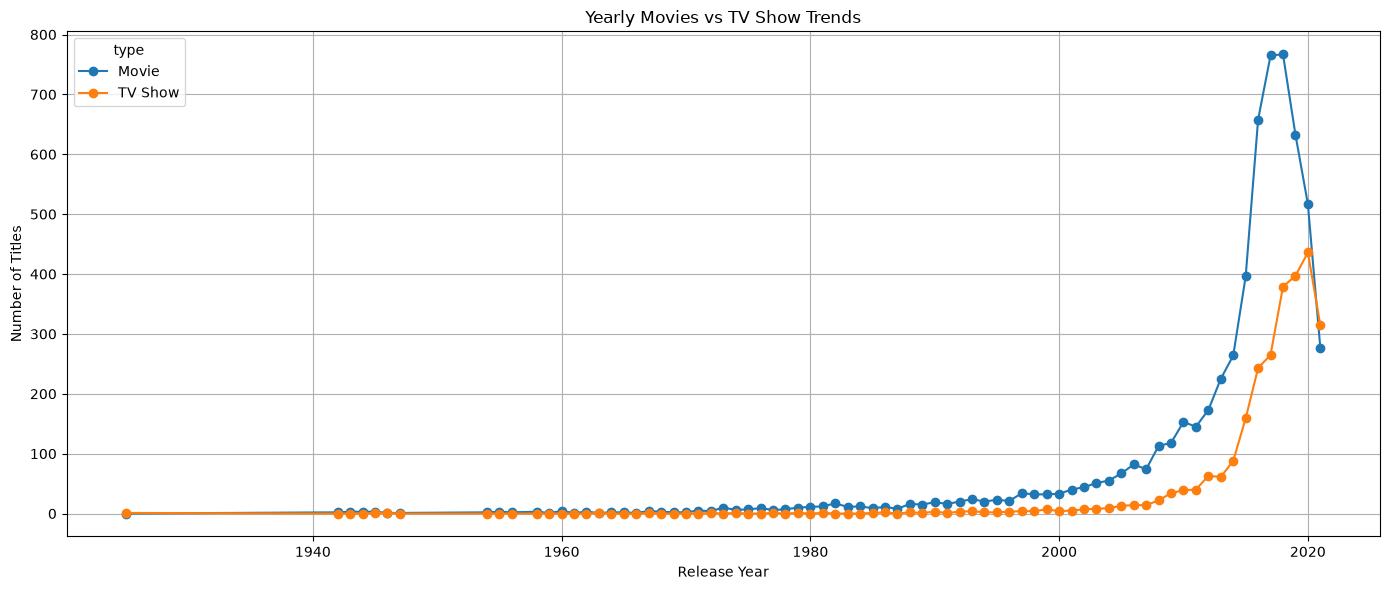

In [52]:
yearly_type.plot(
    figsize=(14,6),
    marker='o'
)

plt.title("Yearly Movies vs TV Show Trends")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)

plt.tight_layout()
plt.show()

In [53]:
trend_data = yearly_content[
    yearly_content["release_year"] >= 2000
].copy()

# create continuos yearly index

years = range(
    trend_data["release_year"].min(),
    trend_data["release_year"].max()+1
)

trend_series = (
    trend_data.set_index("release_year")["content_count"]
    .reindex(years,fill_value=0)
)

trend_series.index.name = "release_year"
trend_series

release_year
2000      37
2001      45
2002      51
2003      59
2004      64
2005      80
2006      96
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: content_count, dtype: int64

In [54]:
# trend test split

test_size = 5
train = trend_series.iloc[:-test_size]
test = trend_series.iloc[-test_size:]
train

release_year
2000     37
2001     45
2002     51
2003     59
2004     64
2005     80
2006     96
2007     88
2008    135
2009    152
2010    192
2011    185
2012    236
2013    286
2014    352
2015    555
2016    901
Name: content_count, dtype: int64

In [55]:

test

release_year
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: content_count, dtype: int64

In [56]:
x_train = train.index.to_numpy().reshape(-1,1)
y_train = train.values

x_test = test.index.to_numpy().reshape(-1,1)
y_test = test.values

lr_model = LinearRegression()
lr_model.fit(x_train,y_train)

# predict test data

lr_prediction = lr_model.predict(x_test)
lr_prediction

array([530.57352941, 566.55882353, 602.54411765, 638.52941176,
       674.51470588])

In [57]:
# train Exponential model

es_model = ExponentialSmoothing(
    train.astype(float),
    trend="add",
    damped_trend=True,
    seasonal=None
).fit(optimized=True)

# predict model evalution
es_predictions = es_model.forecast(len(test))

for year,prediction in es_predictions.items():
    round(prediction,2)

In [58]:
results = pd.DataFrame({
    'Model':[
        "Linear Regression",
        "Exponential Smoothing"
    ],
    "MAE":[
        mean_absolute_error(test,lr_prediction),
        mean_absolute_error(test,es_predictions)
    ],
    "RMSE":[
        np.sqrt(mean_squared_error(test,lr_prediction)),
        np.sqrt(mean_squared_error(test,es_predictions))
    ]
})

results

,Model,MAE,RMSE
0,Linear Regression,380.661765,417.994697
1,Exponential Smoothing,976.750360,1168.832923


In [59]:
final_model = LinearRegression()

x= trend_series.index.to_numpy().reshape(-1,1)
y = trend_series.values

final_model.fit(x,y)

# Generete next 5 years
future_years = np.arange(
    trend_series.index.max()+1,
    trend_series.index.max()+6
).reshape(-1,1)

future_prediction = final_model.predict(future_years)

# content count cannot be negative

future_prediction = np.maximum(future_prediction,0)

#create forecast dataframe

forecast_df = pd.DataFrame({
    "year":future_years.flatten(),
    "predicted_content":np.round(future_prediction).astype(int)
})

In [60]:
forecast_df

,year,predicted_content
0,2022,963
1,2023,1014
2,2024,1065
3,2025,1116
4,2026,1167


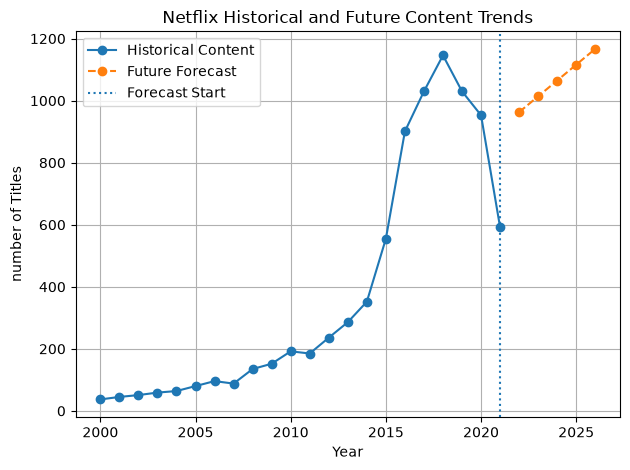

In [61]:
plt.Figure(figsize=(14,6))

#historical data
plt.plot(
    trend_series.index,
    trend_series.values,
    label="Historical Content",
    marker="o"
)

#future predictions
plt.plot(
    forecast_df["year"],
    forecast_df["predicted_content"],
    label="Future Forecast",
    marker="o",
    linestyle="--"
)

plt.axvline(
    trend_series.index.max(),
    linestyle=":",
    label="Forecast Start"
)

plt.title("Netflix Historical and Future Content Trends")
plt.xlabel("Year")
plt.ylabel("number of Titles")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [62]:
forecast_df.to_string(index=False)

' year  predicted_content\n 2022                963\n 2023               1014\n 2024               1065\n 2025               1116\n 2026               1167'

Key Findings and Conclusion

Key Findings

1. Historical Content Trends: The analysis revealed changes in yearly content distribution, with content releases varying across different years.

2. Content Distribution: Movies and TV Shows showed different release patterns over the analyzed period.

3. Forecasting Models: Two forecasting models, Linear Regression and Exponential Smoothing, were implemented and evaluated.

4. Model Performance: Linear Regression performed better than Exponential Smoothing on the test dataset.

5. Evaluation Metrics: Linear Regression achieved an MAE of 380.66 and RMSE of 417.99, while Exponential Smoothing achieved an MAE of 976.75 and RMSE of 1168.83.

6. Future Predictions: Linear Regression forecasted an increasing trend in yearly content counts, from approximately 963 titles in 2022 to 1,167 titles in 2026.

7. Trend Observation: The forecasting results indicate a potential upward trend in historical release-year content distribution.

Conclusion

In this project, historical Netflix content data was analyzed to understand yearly release trends and forecast future content growth.

Two forecasting techniques, Linear Regression and Exponential Smoothing, were implemented and compared using MAE and RMSE evaluation metrics.

Linear Regression achieved lower prediction errors and was selected as the final forecasting model.

The future predictions indicate an increasing trend in content counts over the next five years.

This project provided practical experience in trend analysis, forecasting, predictive modeling, and data visualization using Python.

Note: These forecasts are based on historical release-year distributions and should not be interpreted as actual future Netflix additions.